Data shape: (10000, 2)


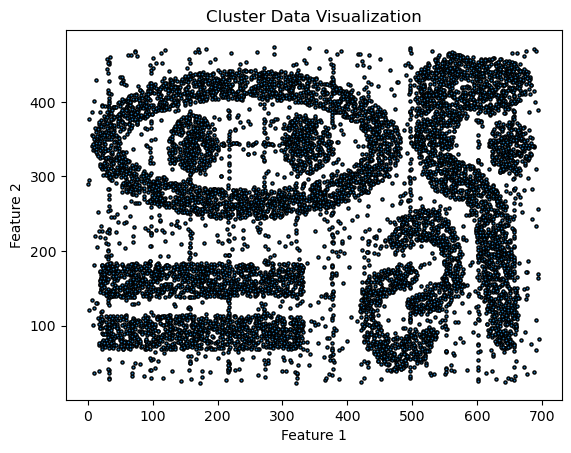


Running K-Means with k = 2
Iteration 1: Time = 3.0602 seconds, Silhouette Score = 0.4686, Calinski-Harabasz Index = 12461.7491
Iteration 2: Time = 2.8103 seconds, Silhouette Score = 0.4830, Calinski-Harabasz Index = 13416.6061
Iteration 3: Time = 1.4493 seconds, Silhouette Score = 0.4841, Calinski-Harabasz Index = 13545.0858


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score, calinski_harabasz_score
import time

def load_data(file_path):
    data = np.loadtxt(file_path)
    return data

def euclidean_distance(x1, x2):
    return np.sqrt(np.sum((x1 - x2) ** 2))

def kmeans(X, k, max_iters=100):
    n_samples, n_features = X.shape
    centroids = X[np.random.choice(n_samples, k, replace=False)]
    silhouette_scores = []
    calinski_scores = []
    for iteration in range(max_iters):
        start_time = time.time()
        labels = np.zeros(n_samples)
        for i in range(n_samples):
            distances = [euclidean_distance(X[i], centroid) for centroid in centroids]
            labels[i] = np.argmin(distances)
        new_centroids = np.zeros((k, n_features))
        for j in range(k):
            cluster_points = X[labels == j]
            if len(cluster_points) > 0:
                new_centroids[j] = np.mean(cluster_points, axis=0)
        if np.all(centroids == new_centroids):
            print(f"Converged at iteration {iteration + 1}")
            break
        centroids = new_centroids
        end_time = time.time()
        elapsed_time = end_time - start_time
        if len(set(labels)) > 1:
            silhouette = silhouette_score(X, labels)
            calinski = calinski_harabasz_score(X, labels)
        else:
            silhouette, calinski = -1, -1
        silhouette_scores.append(silhouette)
        calinski_scores.append(calinski)
        print(f"Iteration {iteration + 1}: Time = {elapsed_time:.4f} seconds, "
              f"Silhouette Score = {silhouette:.4f}, Calinski-Harabasz Index = {calinski:.4f}")
    
    return labels, centroids, silhouette_scores, calinski_scores


file_path = "clusterData1.10k.dat"
clusterData1 = load_data(file_path)
print(f"Data shape: {clusterData1.shape}")
plt.scatter(clusterData1[:, 0], clusterData1[:, 1], s=5, edgecolors='k')
plt.title("Cluster Data Visualization")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()
k_values = [2, 3, 4, 5, 6, 7, 8, 9]
results = {}
for k in k_values:
    print(f"\nRunning K-Means with k = {k}")
    labels, centroids, silhouette_scores, calinski_scores = kmeans(clusterData1, k)
    results[k] = {'silhouette_scores': silhouette_scores,'calinski_scores': calinski_scores}
    plt.scatter(clusterData1[:, 0], clusterData1[:, 1], c=labels, s=5, cmap='viridis', edgecolors='k')
    plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=200, marker='X', label='Centroids')
    plt.title(f"K-Means with k = {k} Clustering")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.legend()
    plt.show()
    print(f"silhouette_scores:{silhouette_scores[-1]}  calinski_scores:{calinski_scores[-1]}")

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
for k in k_values:
    plt.plot(range(1, len(results[k]['silhouette_scores']) + 1),
             results[k]['silhouette_scores'],
             linestyle='-',
             label=f'k = {k}')
plt.title("Silhouette Score vs Iteration")
plt.xlabel("Iteration")
plt.ylabel("Silhouette Score")
plt.legend()
plt.grid(True)
plt.subplot(1, 2, 2)
for k in k_values:
    plt.plot(range(1, len(results[k]['calinski_scores']) + 1),
             results[k]['calinski_scores'],
             linestyle='-',
             label=f'k = {k}')
plt.title("Calinski-Harabasz Index vs Iteration")
plt.xlabel("Iteration")
plt.ylabel("Calinski-Harabasz Index")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Data shape: (10000, 2)


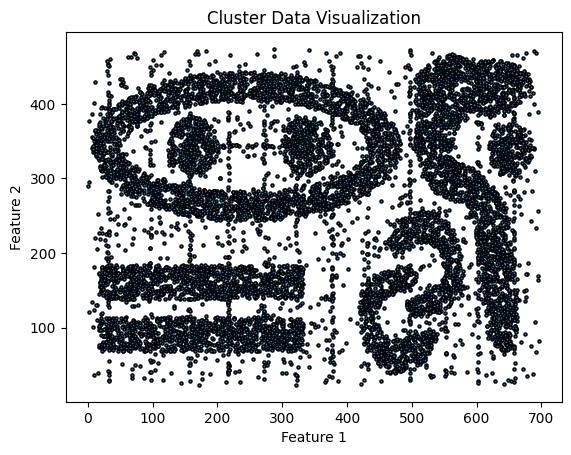


Running K-Means with k = 2
Converged at iteration 11
Final Silhouette Score: 0.4840, Final Calinski-Harabasz Index: 13570.1911

Running K-Means with k = 3
Converged at iteration 28
Final Silhouette Score: 0.4214, Final Calinski-Harabasz Index: 10581.6307

Running K-Means with k = 4
Converged at iteration 20
Final Silhouette Score: 0.3941, Final Calinski-Harabasz Index: 10294.9696

Running K-Means with k = 5
Converged at iteration 13
Final Silhouette Score: 0.4511, Final Calinski-Harabasz Index: 13700.3082

Running K-Means with k = 6
Converged at iteration 33
Final Silhouette Score: 0.4419, Final Calinski-Harabasz Index: 13941.4065

Running K-Means with k = 7
Converged at iteration 14
Final Silhouette Score: 0.4285, Final Calinski-Harabasz Index: 13858.0942

Running K-Means with k = 8
Converged at iteration 59
Final Silhouette Score: 0.3992, Final Calinski-Harabasz Index: 13435.7669

Running K-Means with k = 9
Converged at iteration 42
Final Silhouette Score: 0.4153, Final Calinski-Har

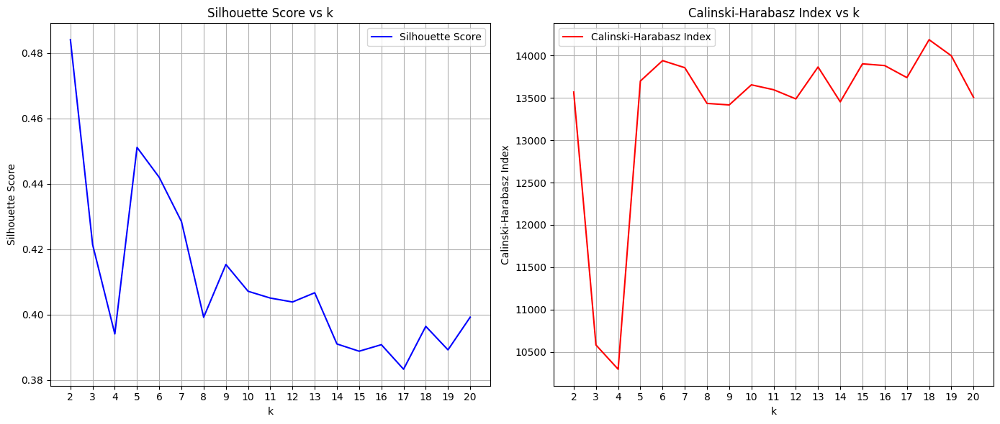

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score, calinski_harabasz_score
import time

def load_data(file_path):
    data = np.loadtxt(file_path)
    return data

def euclidean_distance(x1, x2):
    return np.sqrt(np.sum((x1 - x2) ** 2))

def kmeans(X, k, max_iters=200):
    n_samples, n_features = X.shape
    centroids = X[np.random.choice(n_samples, k, replace=False)]
    silhouette_scores = []
    calinski_scores = []
    for iteration in range(max_iters):
        start_time = time.time()
        labels = np.zeros(n_samples)
        for i in range(n_samples):
            distances = [euclidean_distance(X[i], centroid) for centroid in centroids]
            labels[i] = np.argmin(distances)
        new_centroids = np.zeros((k, n_features))
        for j in range(k):
            cluster_points = X[labels == j]
            if len(cluster_points) > 0:
                new_centroids[j] = np.mean(cluster_points, axis=0)
        if np.all(centroids == new_centroids):
            print(f"Converged at iteration {iteration + 1}")
            break
        centroids = new_centroids
        end_time = time.time()
        elapsed_time = end_time - start_time
        if len(set(labels)) > 1:
            silhouette = silhouette_score(X, labels)
            calinski = calinski_harabasz_score(X, labels)
        else:
            silhouette, calinski = -1, -1
        silhouette_scores.append(silhouette)
        calinski_scores.append(calinski)
        #print(f"Iteration {iteration + 1}: Time = {elapsed_time:.4f} seconds, "
             # f"Silhouette Score = {silhouette:.4f}, Calinski-Harabasz Index = {calinski:.4f}")
    
    return labels, centroids, silhouette_scores, calinski_scores


file_path = "clusterData1.10k.dat"
clusterData1 = load_data(file_path)
print(f"Data shape: {clusterData1.shape}")

plt.scatter(clusterData1[:, 0], clusterData1[:, 1], s=5, edgecolors='k')
plt.title("Cluster Data Visualization")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

k_values = np.arange(2,21,1)
results = {}

for k in k_values:
    print(f"\nRunning K-Means with k = {k}")
    labels, centroids, silhouette_scores, calinski_scores = kmeans(clusterData1, k)
    results[k] = {'silhouette_scores': silhouette_scores, 'calinski_scores': calinski_scores}
    '''plt.scatter(clusterData1[:, 0], clusterData1[:, 1], c=labels, s=5, cmap='viridis', edgecolors='k')
    plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=200, marker='X', label='Centroids')
    plt.title(f"K-Means with k = {k} Clustering")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.legend()
    plt.show()'''

    print(f"Final Silhouette Score: {silhouette_scores[-1]:.4f}, Final Calinski-Harabasz Index: {calinski_scores[-1]:.4f}")
silhouette_final_scores = [results[k]['silhouette_scores'][-1] for k in k_values]
calinski_final_scores = [results[k]['calinski_scores'][-1] for k in k_values]

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.plot(k_values, silhouette_final_scores, linestyle='-', color='b', label='Silhouette Score')
plt.title("Silhouette Score vs k")
plt.xlabel("k")
plt.ylabel("Silhouette Score")
plt.xticks(k_values)
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(k_values, calinski_final_scores, linestyle='-', color='r', label='Calinski-Harabasz Index')
plt.title("Calinski-Harabasz Index vs k")
plt.xlabel("k")
plt.ylabel("Calinski-Harabasz Index")
plt.xticks(k_values)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

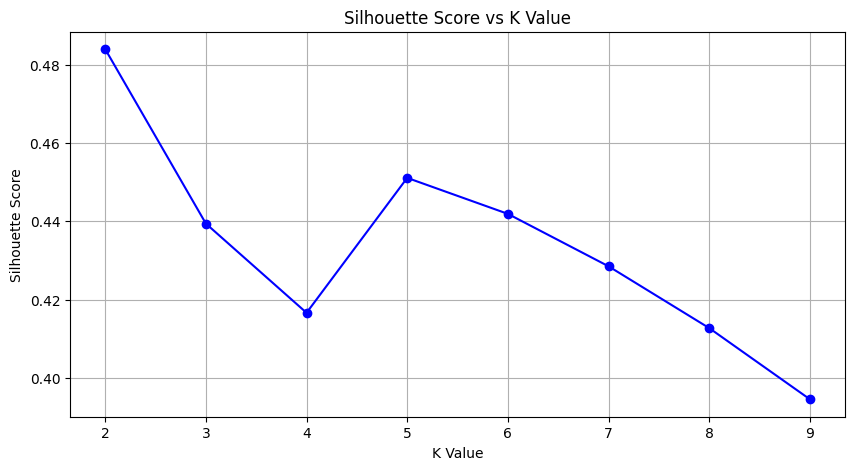

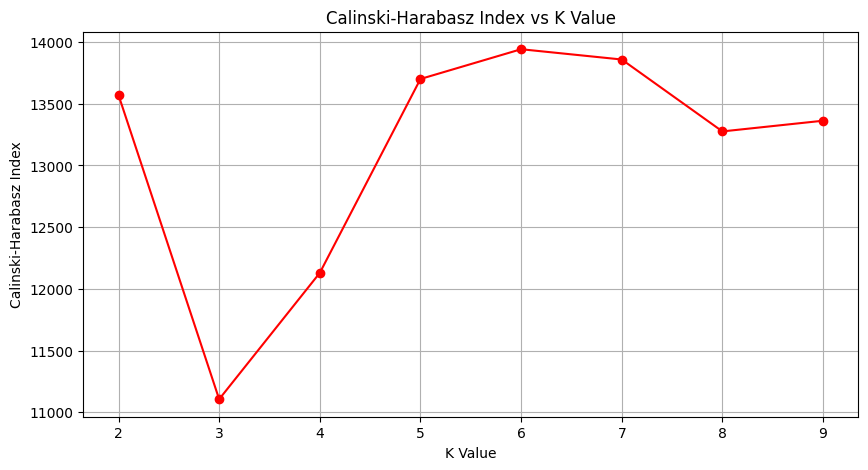

In [3]:
import matplotlib.pyplot as plt

k_values = [2, 3, 4, 5, 6, 7, 8, 9]
silhouette_scores = [0.4840, 0.4394, 0.4166, 0.4511, 0.4419, 0.4285, 0.4127, 0.3945]
calinski_harabasz_index = [13570.2038, 11105.5782, 12129.3588, 13700.3082, 13941.4065, 13858.0525, 13275.4311, 13362.0527]

plt.figure(figsize=(10, 5))
plt.plot(k_values, silhouette_scores, marker='o', linestyle='-', color='b')
plt.title('Silhouette Score vs K Value')
plt.xlabel('K Value')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(k_values, calinski_harabasz_index, marker='o', linestyle='-', color='r')
plt.title('Calinski-Harabasz Index vs K Value')
plt.xlabel('K Value')
plt.ylabel('Calinski-Harabasz Index')
plt.grid(True)
plt.show()

Data shape: (10000, 2)


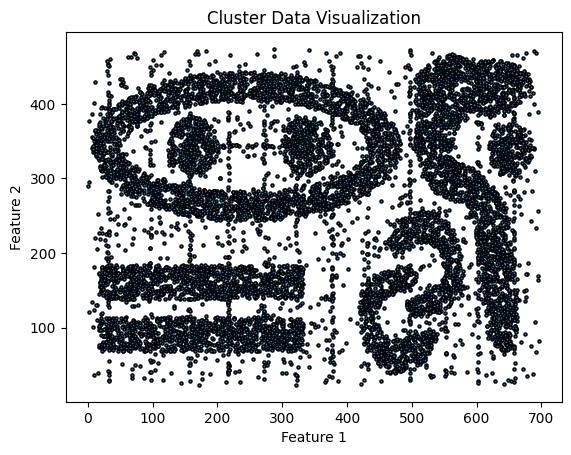

Running DBSCAN with eps = 2
Running DBSCAN with eps = 3
Running DBSCAN with eps = 4
Running DBSCAN with eps = 5
Running DBSCAN with eps = 6
Running DBSCAN with eps = 7
Running DBSCAN with eps = 8
Running DBSCAN with eps = 9
Running DBSCAN with eps = 10
Running DBSCAN with eps = 11
Running DBSCAN with eps = 12
Running DBSCAN with eps = 13
Running DBSCAN with eps = 14
Running DBSCAN with eps = 15
Running DBSCAN with eps = 16
Running DBSCAN with eps = 17
Running DBSCAN with eps = 18
Running DBSCAN with eps = 19
Running DBSCAN with eps = 20
Running DBSCAN with eps = 21
Running DBSCAN with eps = 22
Running DBSCAN with eps = 23
Running DBSCAN with eps = 24
Running DBSCAN with eps = 25
Running DBSCAN with eps = 26
Running DBSCAN with eps = 27
Running DBSCAN with eps = 28
Running DBSCAN with eps = 29
Running DBSCAN with eps = 30
Running DBSCAN with eps = 31
Running DBSCAN with eps = 32
Running DBSCAN with eps = 33
Running DBSCAN with eps = 34
Running DBSCAN with eps = 35
Running DBSCAN with ep

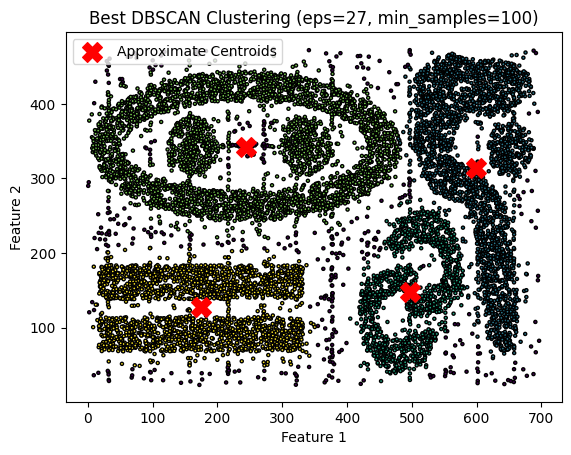

'plt.figure(figsize=(12, 5))\n\n# Silhouette Score 图\nplt.subplot(1, 2, 1)\nfor (eps, min_samples) in results:\n    plt.scatter([eps], [results[(eps, min_samples)][\'silhouette_score\']], label=f\'eps={eps}, min_samples={min_samples}\')\nplt.title("Silhouette Score vs eps and min_samples")\nplt.xlabel("eps")\nplt.ylabel("Silhouette Score")\nplt.legend()\nplt.grid(True)\n\n# Calinski-Harabasz Index 图\nplt.subplot(1, 2, 2)\nfor (eps, min_samples) in results:\n    plt.scatter([eps], [results[(eps, min_samples)][\'calinski_score\']], label=f\'eps={eps}, min_samples={min_samples}\')\nplt.title("Calinski-Harabasz Index vs eps and min_samples")\nplt.xlabel("eps")\nplt.ylabel("Calinski-Harabasz Index")\nplt.legend()\nplt.grid(True)\n\nplt.tight_layout()\nplt.show()'

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from scipy.spatial import cKDTree
import time

def load_data(file_path):
    data = np.loadtxt(file_path)
    return data

def dbscan_optimized(data, eps, min_samples):
    n_points = len(data)
    labels = np.zeros(n_points) 
    cluster_id = 0
    tree = cKDTree(data)
    for point_idx in range(n_points):
        if labels[point_idx] != 0: 
            continue
        neighbors = tree.query_ball_point(data[point_idx], eps)

        if len(neighbors) < min_samples:
            labels[point_idx] = -1
        else:
            cluster_id += 1
            labels[point_idx] = cluster_id
            stack = neighbors.copy()
            while stack:
                neighbor_idx = stack.pop()
                if labels[neighbor_idx] == -1:
                    labels[neighbor_idx] = cluster_id
                elif labels[neighbor_idx] == 0: 
                    labels[neighbor_idx] = cluster_id
                    new_neighbors = tree.query_ball_point(data[neighbor_idx], eps)
                    if len(new_neighbors) >= min_samples: 
                        stack += new_neighbors
    return labels

file_path = "/kaggle/input/clusterdata1/clusterData1.10k.dat"
clusterData1 = load_data(file_path)
print(f"Data shape: {clusterData1.shape}")

plt.scatter(clusterData1[:, 0], clusterData1[:, 1], s=5, edgecolors='k')
plt.title("Cluster Data Visualization")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

eps_values = np.arange(2, 101, 1)
min_samples_values = np.arange(10, 101, 10)
results = {}

for eps in eps_values:
    print(f"Running DBSCAN with eps = {eps}")
    for min_samples in min_samples_values:
        start_time = time.time()
        labels = dbscan_optimized(clusterData1, eps, min_samples)
        end_time = time.time()
        elapsed_time = end_time - start_time
        if len(set(labels)) > 1: 
            silhouette = silhouette_score(clusterData1, labels)
            calinski = calinski_harabasz_score(clusterData1, labels)
        else:
            silhouette, calinski = -1, -1

        results[(eps, min_samples)] = {'silhouette_score': silhouette,'calinski_score': calinski,'time': elapsed_time,'labels': labels}
        unique_labels = np.unique(labels)
        centroids = []
        for label in unique_labels:
            if label != -1: 
                cluster_points = clusterData1[labels == label]
                centroid = np.mean(cluster_points, axis=0)
                centroids.append(centroid)
        centroids = np.array(centroids)
        '''plt.scatter(clusterData1[:, 0], clusterData1[:, 1], c=labels, s=5, cmap='viridis', edgecolors='k')
        if len(centroids) > 0:  # 添加条件判断，避免空的 centroids 数组
            plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=200, marker='X', label='Approximate Centroids')
            plt.legend(loc='upper left')
        plt.title(f"DBSCAN (eps={eps}, min_samples={min_samples}) Clustering")
        plt.xlabel("Feature 1")
        plt.ylabel("Feature 2")
        plt.show()'''


best_key = max(results.keys(), key=lambda k: results[k]['silhouette_score'])
best_result = results[best_key] 

print("\nBest Parameters:")
print(f"eps = {best_key[0]}, min_samples = {best_key[1]}")
print(f"Silhouette Score = {best_result['silhouette_score']:.4f}, Calinski-Harabasz Index = {best_result['calinski_score']:.4f}")

labels = best_result['labels']
unique_labels = np.unique(labels)
centroids = []
for label in unique_labels:
    if label != -1:
        cluster_points = clusterData1[labels == label]
        centroid = np.mean(cluster_points, axis=0)
        centroids.append(centroid)
centroids = np.array(centroids)

plt.scatter(clusterData1[:, 0], clusterData1[:, 1], c=labels, s=5, cmap='viridis', edgecolors='k')
if len(centroids) > 0: 
    plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=200, marker='X', label='Approximate Centroids')
    plt.legend(loc='upper left')
plt.title(f"Best DBSCAN Clustering (eps={best_key[0]}, min_samples={best_key[1]})")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

'''plt.figure(figsize=(12, 5))

# Silhouette Score 图
plt.subplot(1, 2, 1)
for (eps, min_samples) in results:
    plt.scatter([eps], [results[(eps, min_samples)]['silhouette_score']], label=f'eps={eps}, min_samples={min_samples}')
plt.title("Silhouette Score vs eps and min_samples")
plt.xlabel("eps")
plt.ylabel("Silhouette Score")
plt.legend()
plt.grid(True)

# Calinski-Harabasz Index 图
plt.subplot(1, 2, 2)
for (eps, min_samples) in results:
    plt.scatter([eps], [results[(eps, min_samples)]['calinski_score']], label=f'eps={eps}, min_samples={min_samples}')
plt.title("Calinski-Harabasz Index vs eps and min_samples")
plt.xlabel("eps")
plt.ylabel("Calinski-Harabasz Index")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()'''

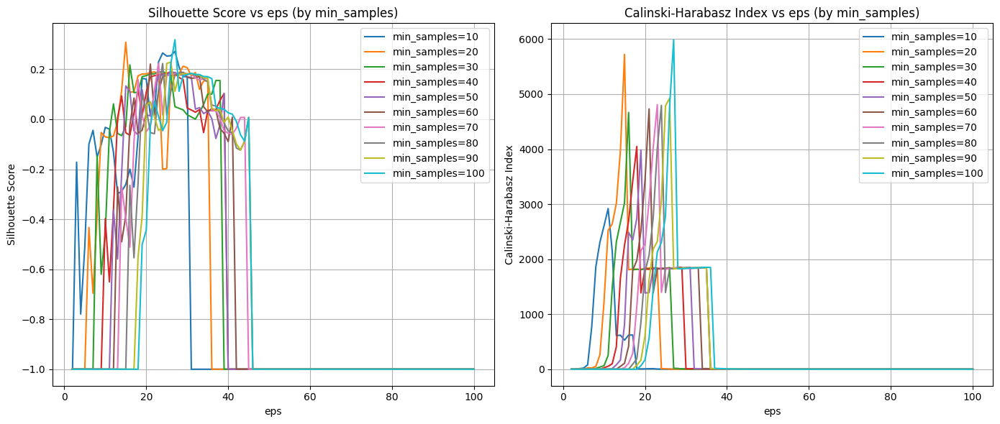

In [5]:
from collections import defaultdict

min_samples_to_eps_silhouette = defaultdict(list)
min_samples_to_eps_calinski = defaultdict(list)

for (eps, min_samples), metrics in results.items():
    min_samples_to_eps_silhouette[min_samples].append((eps, metrics['silhouette_score']))
    min_samples_to_eps_calinski[min_samples].append((eps, metrics['calinski_score']))

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
for min_samples, eps_silhouette in min_samples_to_eps_silhouette.items():
    eps_values = [x[0] for x in eps_silhouette]
    silhouette_scores = [x[1] for x in eps_silhouette]
    plt.plot(eps_values, silhouette_scores, linestyle='-', label=f'min_samples={min_samples}')
plt.title('Silhouette Score vs eps (by min_samples)')
plt.xlabel('eps')
plt.ylabel('Silhouette Score')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
for min_samples, eps_calinski in min_samples_to_eps_calinski.items():
    eps_values = [x[0] for x in eps_calinski]
    calinski_scores = [x[1] for x in eps_calinski]
    plt.plot(eps_values, calinski_scores, linestyle='-', label=f'min_samples={min_samples}')
plt.title('Calinski-Harabasz Index vs eps (by min_samples)')
plt.xlabel('eps')
plt.ylabel('Calinski-Harabasz Index')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

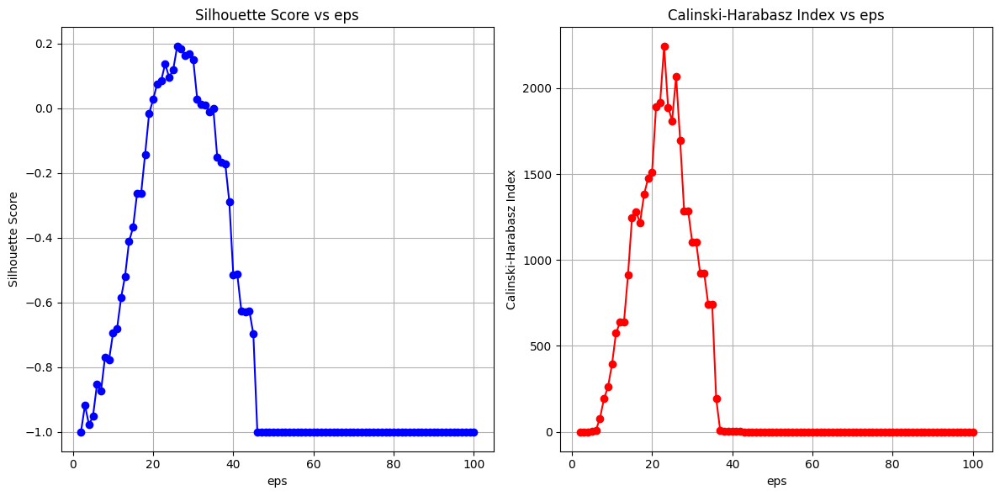

In [6]:
eps_list = []
silhouette_scores = []
calinski_scores = []

for (eps, min_samples), metrics in results.items():
    eps_list.append(eps)
    silhouette_scores.append(metrics['silhouette_score'])
    calinski_scores.append(metrics['calinski_score'])

from collections import defaultdict

eps_to_silhouette = defaultdict(list)
eps_to_calinski = defaultdict(list)

for eps, silhouette, calinski in zip(eps_list, silhouette_scores, calinski_scores):
    eps_to_silhouette[eps].append(silhouette)
    eps_to_calinski[eps].append(calinski)

avg_eps = sorted(eps_to_silhouette.keys())
avg_silhouette = [np.mean(eps_to_silhouette[eps]) for eps in avg_eps]
avg_calinski = [np.mean(eps_to_calinski[eps]) for eps in avg_eps]

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(avg_eps, avg_silhouette, marker='o', linestyle='-', color='b')
plt.title('Silhouette Score vs eps')
plt.xlabel('eps')
plt.ylabel('Silhouette Score')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(avg_eps, avg_calinski, marker='o', linestyle='-', color='r')
plt.title('Calinski-Harabasz Index vs eps')
plt.xlabel('eps')
plt.ylabel('Calinski-Harabasz Index')
plt.grid(True)

plt.tight_layout()
plt.show()


Best Parameters:
eps = 27, min_samples = 100
Silhouette Score = 0.3182, Calinski-Harabasz Index = 5988.6987


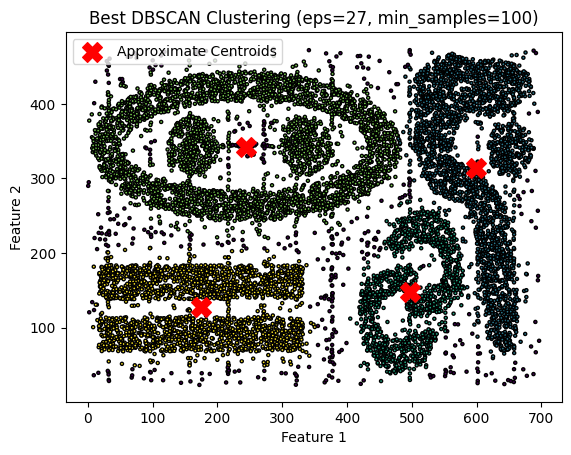

In [7]:
best_key = max(results.keys(), key=lambda k: results[k]['calinski_score'])  
best_result = results[best_key]  
print("\nBest Parameters:")
print(f"eps = {best_key[0]}, min_samples = {best_key[1]}")
print(f"Silhouette Score = {best_result['silhouette_score']:.4f}, Calinski-Harabasz Index = {best_result['calinski_score']:.4f}")

labels = best_result['labels']
unique_labels = np.unique(labels)
centroids = []
for label in unique_labels:
    if label != -1: 
        cluster_points = clusterData1[labels == label]
        centroid = np.mean(cluster_points, axis=0)
        centroids.append(centroid)
centroids = np.array(centroids)

plt.scatter(clusterData1[:, 0], clusterData1[:, 1], c=labels, s=5, cmap='viridis', edgecolors='k')
if len(centroids) > 0:  
    plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=200, marker='X', label='Approximate Centroids')
    plt.legend(loc='upper left')
plt.title(f"Best DBSCAN Clustering (eps={best_key[0]}, min_samples={best_key[1]})")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Data shape: (10000, 2)


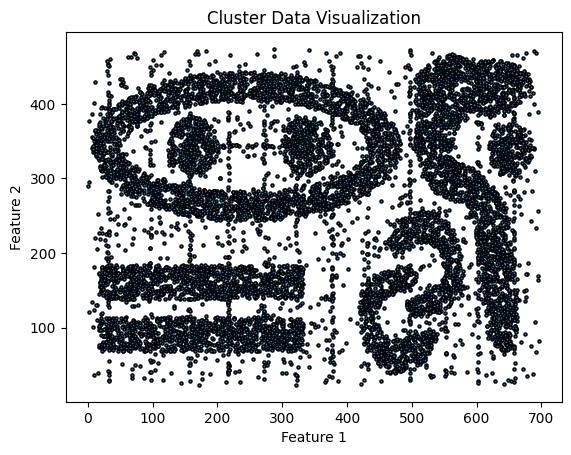


Running SLink with k = 2
Time = 1.4930 seconds, Silhouette Score = 0.1671, Calinski-Harabasz Index = 11.6186


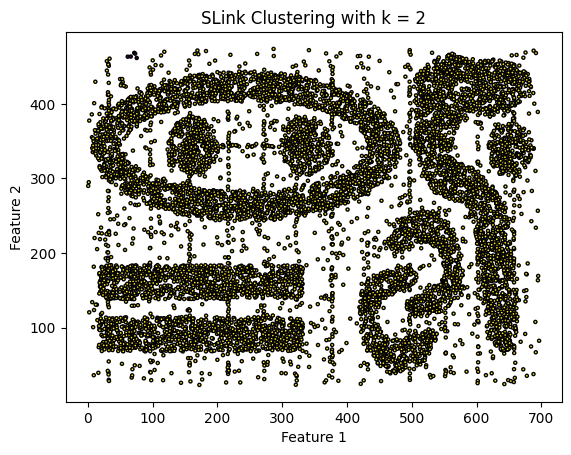

Silhouette Score = 0.1671, Calinski-Harabasz Index = 11.6186

Running SLink with k = 3
Time = 1.5157 seconds, Silhouette Score = -0.0645, Calinski-Harabasz Index = 6.7239


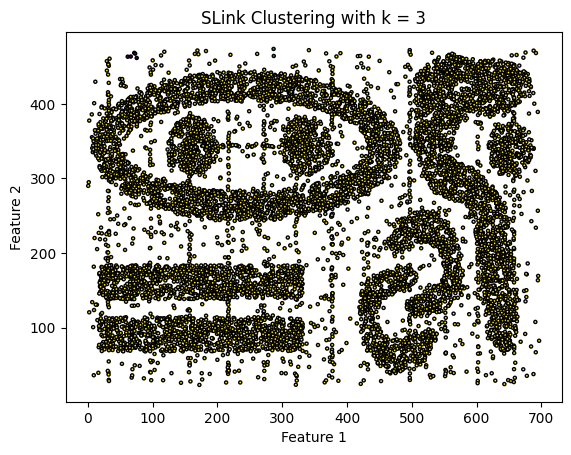

Silhouette Score = -0.0645, Calinski-Harabasz Index = 6.7239

Running SLink with k = 4
Time = 1.4656 seconds, Silhouette Score = -0.2429, Calinski-Harabasz Index = 5.3141


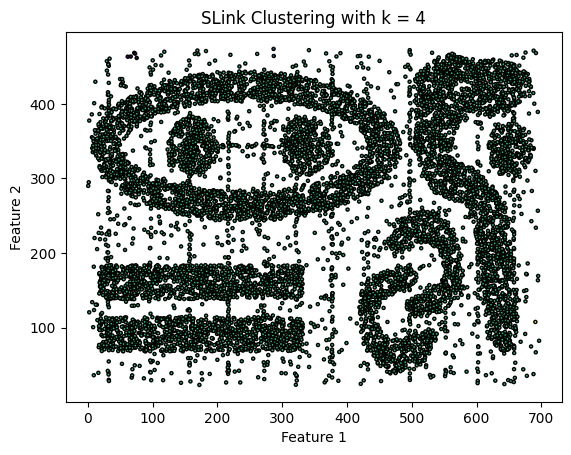

Silhouette Score = -0.2429, Calinski-Harabasz Index = 5.3141

Running SLink with k = 5
Time = 1.4610 seconds, Silhouette Score = -0.2474, Calinski-Harabasz Index = 4.2299


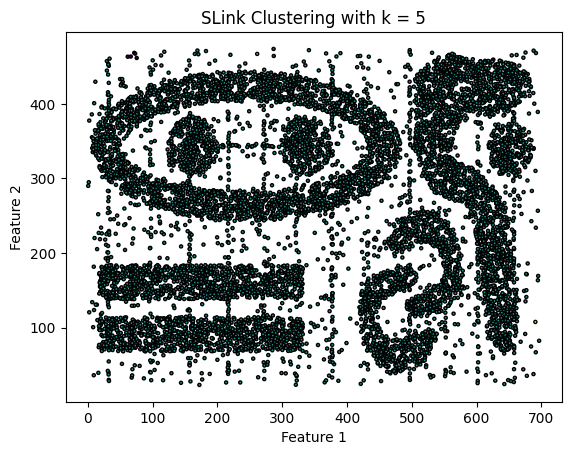

Silhouette Score = -0.2474, Calinski-Harabasz Index = 4.2299

Running SLink with k = 6
Time = 1.4569 seconds, Silhouette Score = -0.3243, Calinski-Harabasz Index = 4.3362


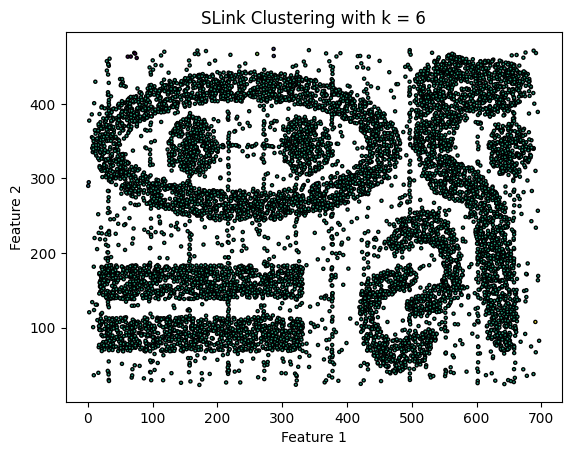

Silhouette Score = -0.3243, Calinski-Harabasz Index = 4.3362

Running SLink with k = 7
Time = 1.5036 seconds, Silhouette Score = -0.4782, Calinski-Harabasz Index = 3.6164


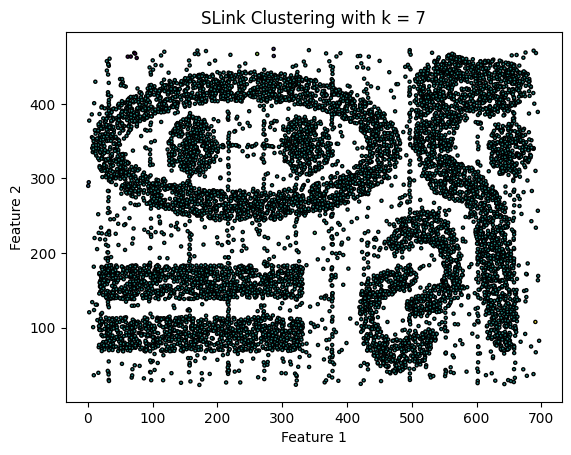

Silhouette Score = -0.4782, Calinski-Harabasz Index = 3.6164

Running SLink with k = 8
Time = 1.4524 seconds, Silhouette Score = -0.5335, Calinski-Harabasz Index = 3.1903


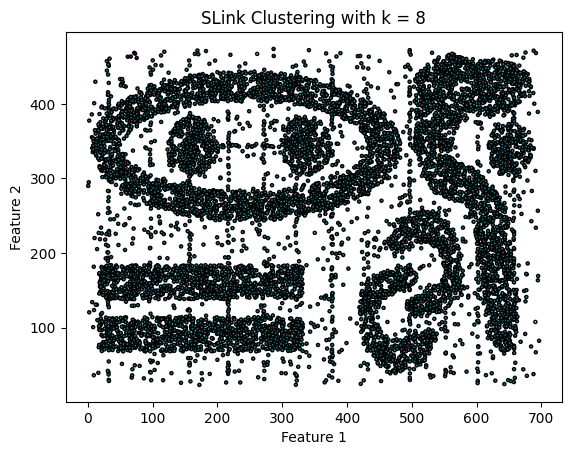

Silhouette Score = -0.5335, Calinski-Harabasz Index = 3.1903

Running SLink with k = 9
Time = 1.4743 seconds, Silhouette Score = -0.5364, Calinski-Harabasz Index = 2.9350


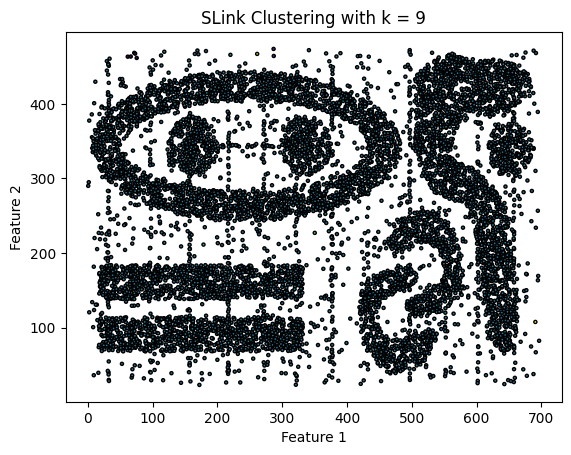

Silhouette Score = -0.5364, Calinski-Harabasz Index = 2.9350


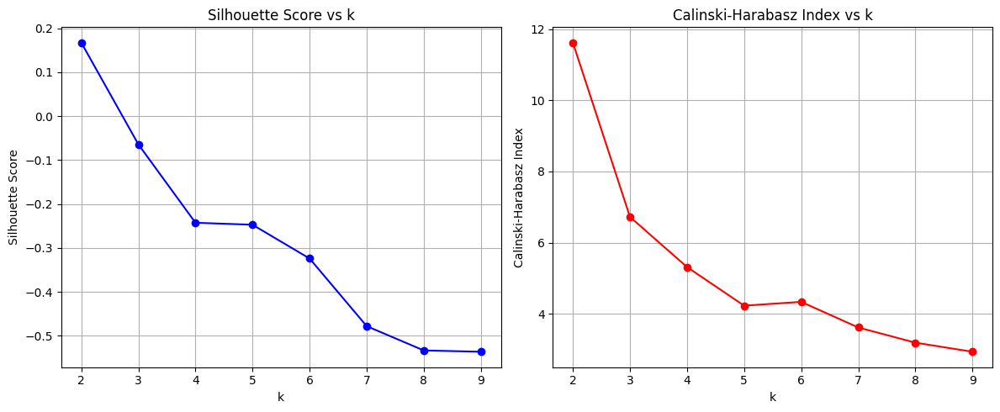

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, fcluster
import time

def load_data(file_path):
    data = np.loadtxt(file_path)
    return data

def slink(X, k):
    start_time = time.time()
    Z = linkage(X, method='single')
    labels = fcluster(Z, t=k, criterion='maxclust')  
    end_time = time.time()
    elapsed_time = end_time - start_time
    if len(set(labels)) > 1: 
        silhouette = silhouette_score(X, labels)
        calinski = calinski_harabasz_score(X, labels)
    else:
        silhouette, calinski = -1, -1
    
    print(f"Time = {elapsed_time:.4f} seconds, Silhouette Score = {silhouette:.4f}, Calinski-Harabasz Index = {calinski:.4f}")
    
    return labels, silhouette, calinski

file_path = "/kaggle/input/clusterdata1/clusterData1.10k.dat"
clusterData1 = load_data(file_path)
print(f"Data shape: {clusterData1.shape}")

plt.scatter(clusterData1[:, 0], clusterData1[:, 1], s=5, edgecolors='k')
plt.title("Cluster Data Visualization")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

k_values = [2, 3, 4, 5, 6, 7, 8, 9]
results = {}

for k in k_values:
    print(f"\nRunning SLink with k = {k}")
    labels, silhouette, calinski = slink(clusterData1, k)
    results[k] = {'silhouette': silhouette, 'calinski': calinski, 'labels': labels}
    plt.scatter(clusterData1[:, 0], clusterData1[:, 1], c=labels, s=5, cmap='viridis', edgecolors='k')
    plt.title(f"SLink Clustering with k = {k}")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()
    
    print(f"Silhouette Score = {silhouette:.4f}, Calinski-Harabasz Index = {calinski:.4f}")


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(k_values, [results[k]['silhouette'] for k in k_values], marker='o', linestyle='-', color='b')
plt.title("Silhouette Score vs k")
plt.xlabel("k")
plt.ylabel("Silhouette Score")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(k_values, [results[k]['calinski'] for k in k_values], marker='o', linestyle='-', color='r')
plt.title("Calinski-Harabasz Index vs k")
plt.xlabel("k")
plt.ylabel("Calinski-Harabasz Index")
plt.grid(True)

plt.tight_layout()
plt.show()

Data shape: (10000, 2)


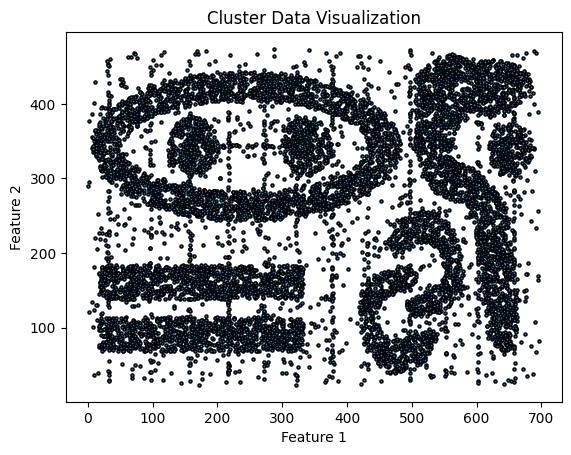


Running SLink with k = 2
Time = 4.0591 seconds, Silhouette Score = 0.4188, Calinski-Harabasz Index = 9736.9948


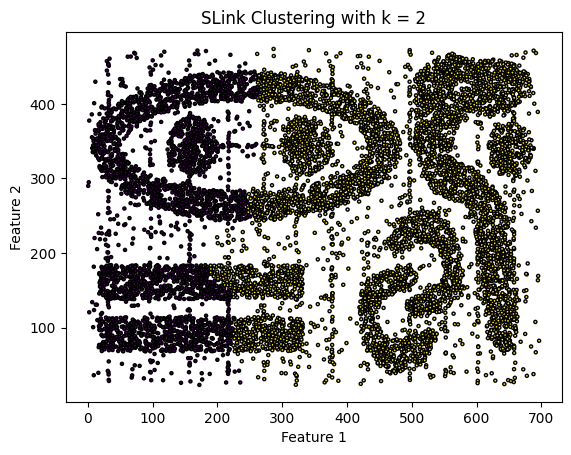

Silhouette Score = 0.4188, Calinski-Harabasz Index = 9736.9948

Running SLink with k = 3
Time = 4.1776 seconds, Silhouette Score = 0.3202, Calinski-Harabasz Index = 8945.3514


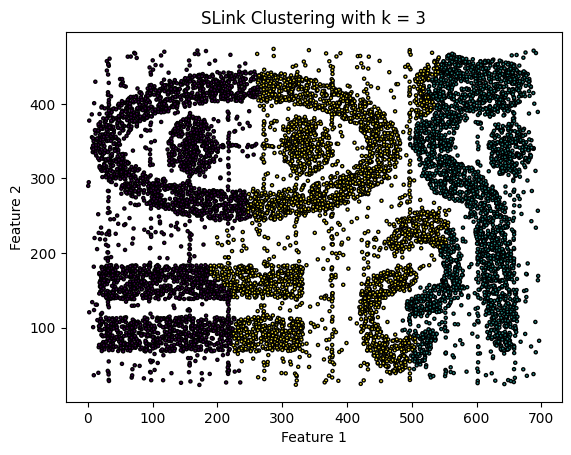

Silhouette Score = 0.3202, Calinski-Harabasz Index = 8945.3514

Running SLink with k = 4
Time = 4.1544 seconds, Silhouette Score = 0.3031, Calinski-Harabasz Index = 8114.7462


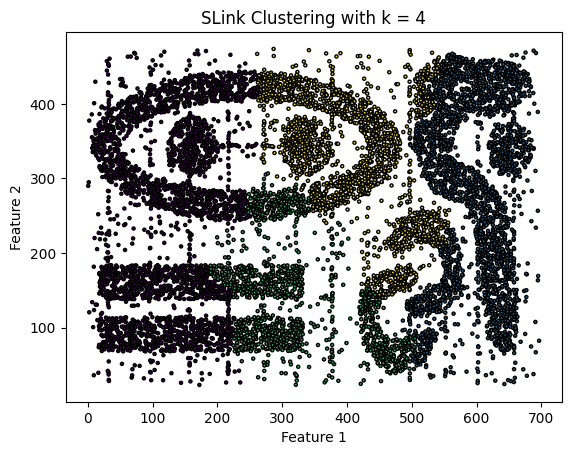

Silhouette Score = 0.3031, Calinski-Harabasz Index = 8114.7462

Running SLink with k = 5
Time = 4.0452 seconds, Silhouette Score = 0.3126, Calinski-Harabasz Index = 8459.0289


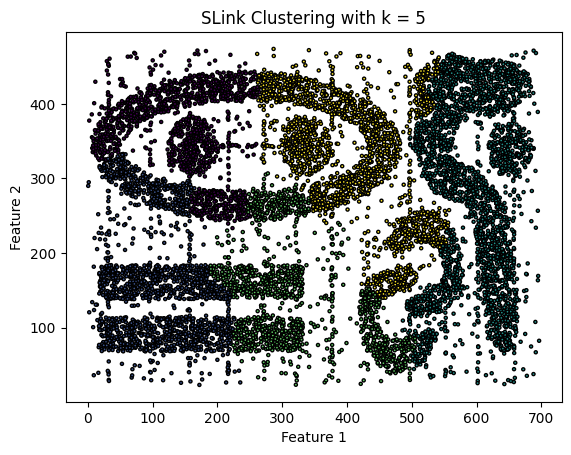

Silhouette Score = 0.3126, Calinski-Harabasz Index = 8459.0289

Running SLink with k = 6
Time = 4.0330 seconds, Silhouette Score = 0.3395, Calinski-Harabasz Index = 9952.3427


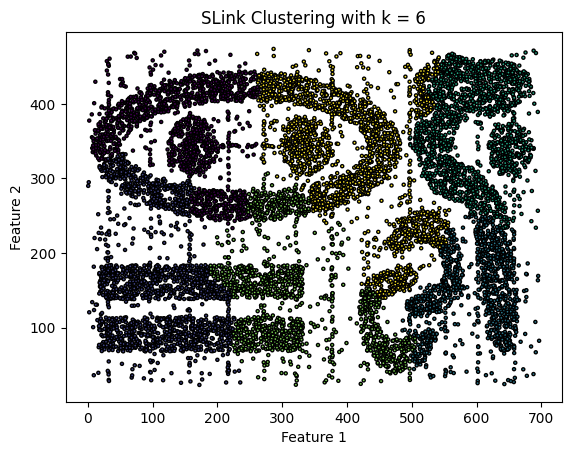

Silhouette Score = 0.3395, Calinski-Harabasz Index = 9952.3427

Running SLink with k = 7
Time = 4.0321 seconds, Silhouette Score = 0.3442, Calinski-Harabasz Index = 9947.8351


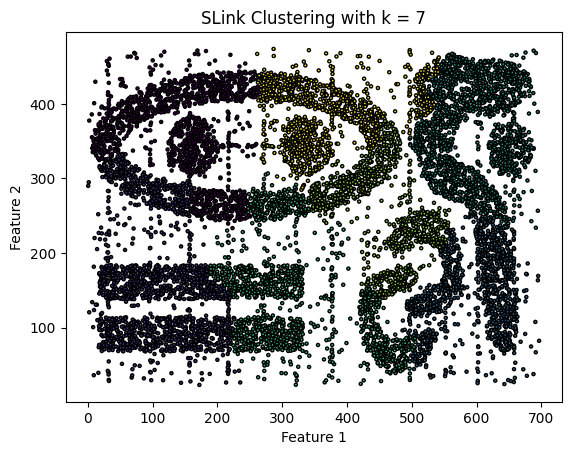

Silhouette Score = 0.3442, Calinski-Harabasz Index = 9947.8351

Running SLink with k = 8
Time = 4.0717 seconds, Silhouette Score = 0.3190, Calinski-Harabasz Index = 9803.3964


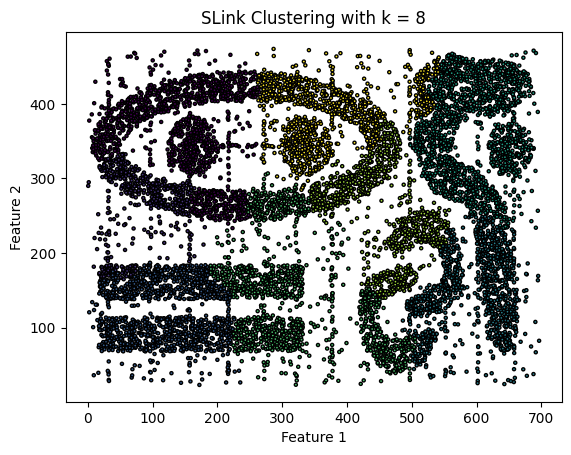

Silhouette Score = 0.3190, Calinski-Harabasz Index = 9803.3964

Running SLink with k = 9
Time = 3.9975 seconds, Silhouette Score = 0.3259, Calinski-Harabasz Index = 9776.5075


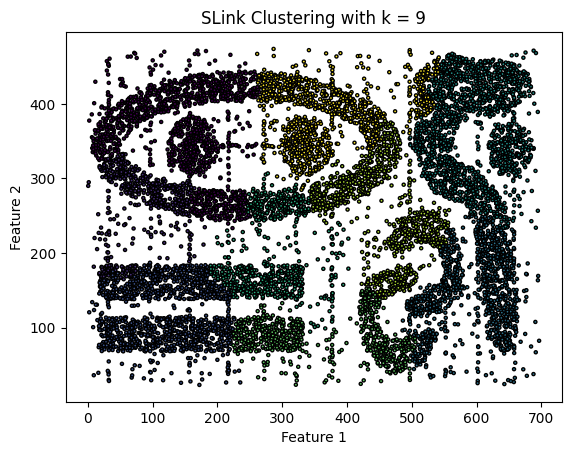

Silhouette Score = 0.3259, Calinski-Harabasz Index = 9776.5075


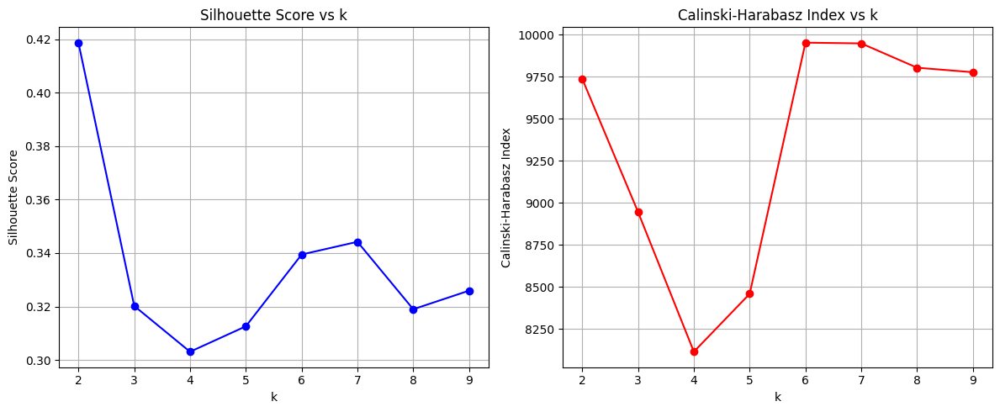

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, fcluster
import time

def load_data(file_path):
    data = np.loadtxt(file_path)
    return data

def slink(X, k):
    start_time = time.time()
    Z = linkage(X, method='complete')
    labels = fcluster(Z, t=k, criterion='maxclust')  
    end_time = time.time()
    elapsed_time = end_time - start_time
    if len(set(labels)) > 1: 
        silhouette = silhouette_score(X, labels)
        calinski = calinski_harabasz_score(X, labels)
    else:
        silhouette, calinski = -1, -1
    
    print(f"Time = {elapsed_time:.4f} seconds, Silhouette Score = {silhouette:.4f}, Calinski-Harabasz Index = {calinski:.4f}")
    
    return labels, silhouette, calinski

file_path = "/kaggle/input/clusterdata1/clusterData1.10k.dat"
clusterData1 = load_data(file_path)
print(f"Data shape: {clusterData1.shape}")

plt.scatter(clusterData1[:, 0], clusterData1[:, 1], s=5, edgecolors='k')
plt.title("Cluster Data Visualization")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

k_values = [2, 3, 4, 5, 6, 7, 8, 9]
results = {}

for k in k_values:
    print(f"\nRunning SLink with k = {k}")
    labels, silhouette, calinski = slink(clusterData1, k)
    results[k] = {'silhouette': silhouette, 'calinski': calinski, 'labels': labels}
    plt.scatter(clusterData1[:, 0], clusterData1[:, 1], c=labels, s=5, cmap='viridis', edgecolors='k')
    plt.title(f"SLink Clustering with k = {k}")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()
    
    print(f"Silhouette Score = {silhouette:.4f}, Calinski-Harabasz Index = {calinski:.4f}")


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(k_values, [results[k]['silhouette'] for k in k_values], marker='o', linestyle='-', color='b')
plt.title("Silhouette Score vs k")
plt.xlabel("k")
plt.ylabel("Silhouette Score")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(k_values, [results[k]['calinski'] for k in k_values], marker='o', linestyle='-', color='r')
plt.title("Calinski-Harabasz Index vs k")
plt.xlabel("k")
plt.ylabel("Calinski-Harabasz Index")
plt.grid(True)

plt.tight_layout()
plt.show()

Data shape: (10000, 2)


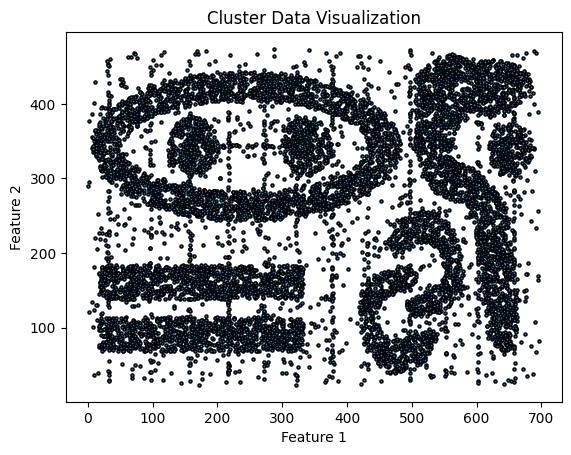


Running SLink with k = 2
Time = 4.3753 seconds, Silhouette Score = 0.4757, Calinski-Harabasz Index = 13104.3581


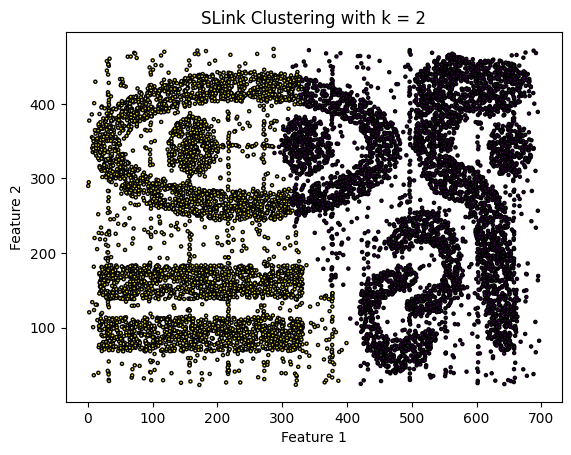

Silhouette Score = 0.4757, Calinski-Harabasz Index = 13104.3581

Running SLink with k = 3
Time = 4.3400 seconds, Silhouette Score = 0.4283, Calinski-Harabasz Index = 10145.6088


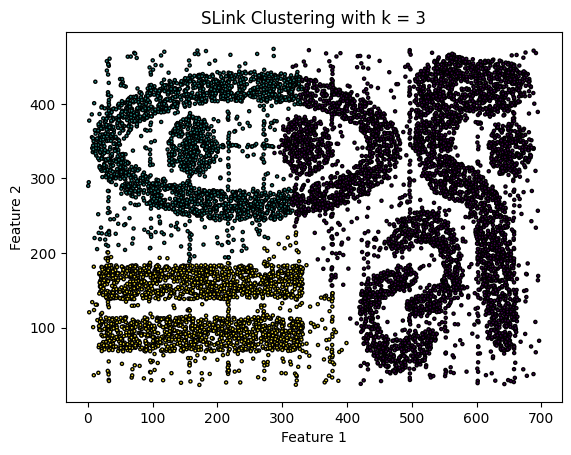

Silhouette Score = 0.4283, Calinski-Harabasz Index = 10145.6088

Running SLink with k = 4
Time = 4.3613 seconds, Silhouette Score = 0.3951, Calinski-Harabasz Index = 11199.3260


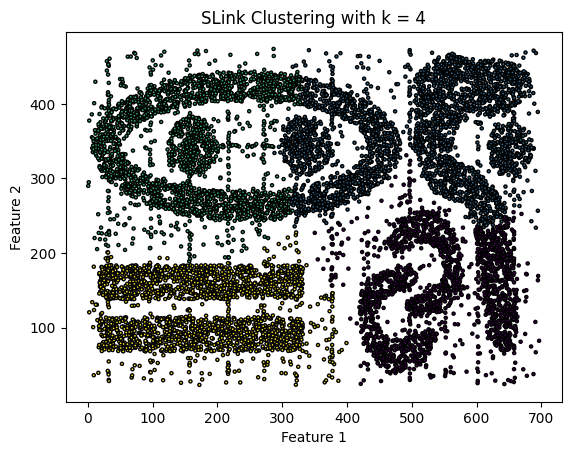

Silhouette Score = 0.3951, Calinski-Harabasz Index = 11199.3260

Running SLink with k = 5
Time = 4.6080 seconds, Silhouette Score = 0.4186, Calinski-Harabasz Index = 12441.7454


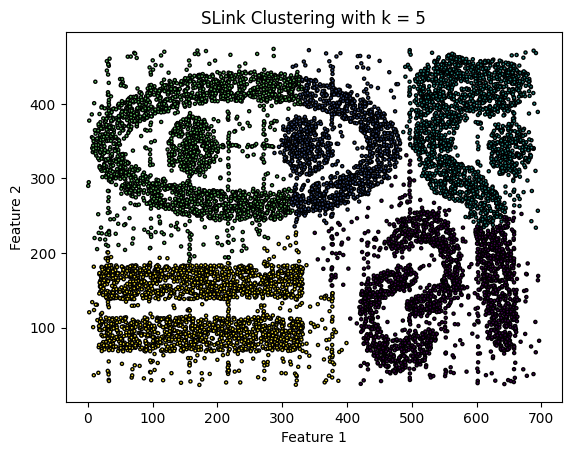

Silhouette Score = 0.4186, Calinski-Harabasz Index = 12441.7454

Running SLink with k = 6
Time = 4.3392 seconds, Silhouette Score = 0.4012, Calinski-Harabasz Index = 12264.6614


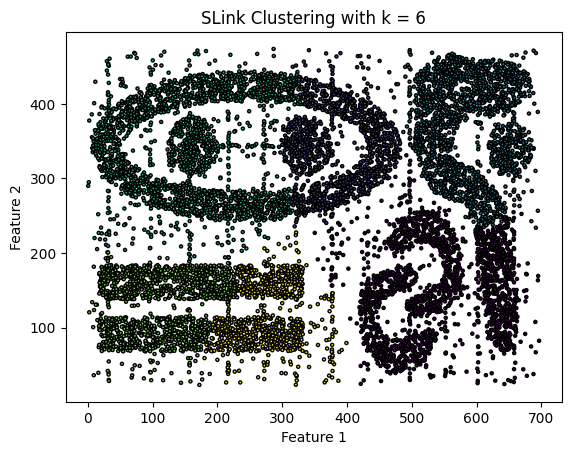

Silhouette Score = 0.4012, Calinski-Harabasz Index = 12264.6614

Running SLink with k = 7
Time = 4.4556 seconds, Silhouette Score = 0.3779, Calinski-Harabasz Index = 11715.2987


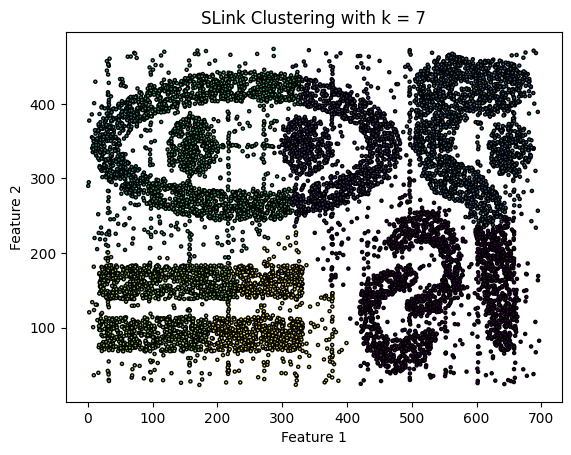

Silhouette Score = 0.3779, Calinski-Harabasz Index = 11715.2987

Running SLink with k = 8
Time = 4.5499 seconds, Silhouette Score = 0.3678, Calinski-Harabasz Index = 11803.1123


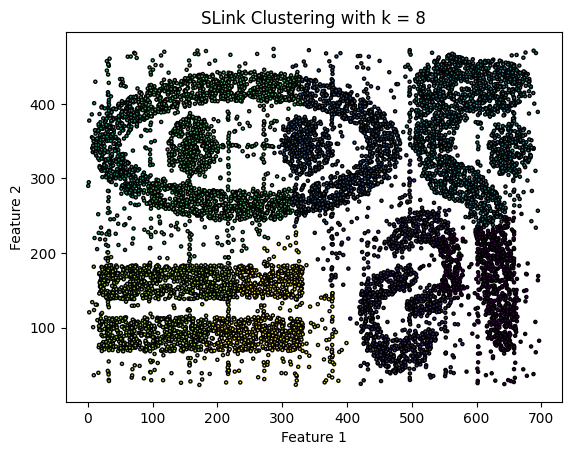

Silhouette Score = 0.3678, Calinski-Harabasz Index = 11803.1123

Running SLink with k = 9
Time = 4.3687 seconds, Silhouette Score = 0.3923, Calinski-Harabasz Index = 11985.4603


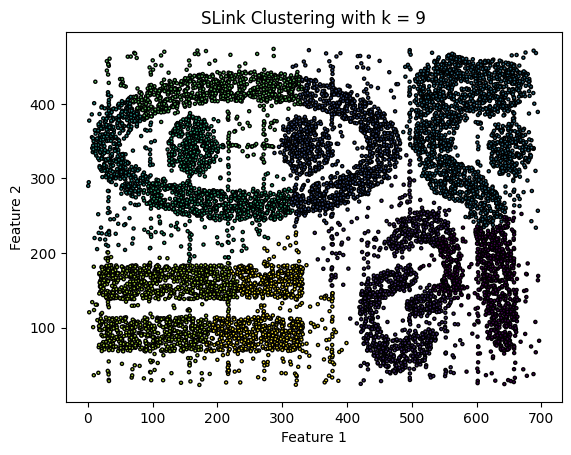

Silhouette Score = 0.3923, Calinski-Harabasz Index = 11985.4603


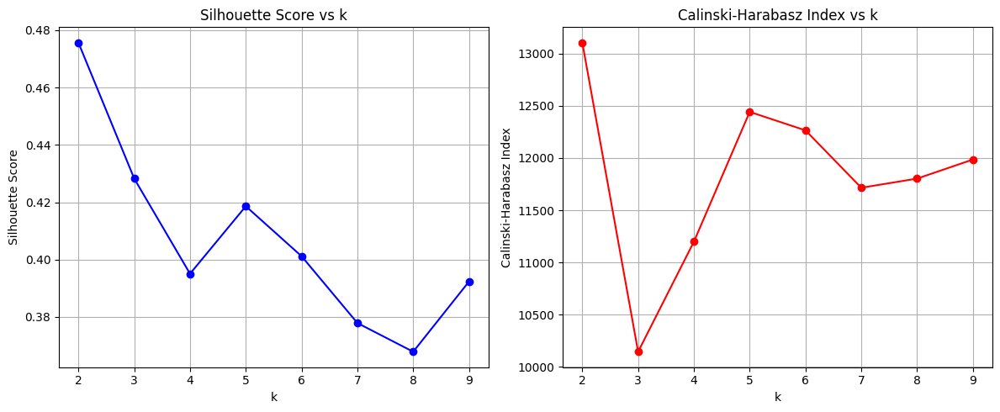

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, fcluster
import time

def load_data(file_path):
    data = np.loadtxt(file_path)
    return data

def slink(X, k):
    start_time = time.time()
    Z = linkage(X, method='average')
    labels = fcluster(Z, t=k, criterion='maxclust')  
    end_time = time.time()
    elapsed_time = end_time - start_time
    if len(set(labels)) > 1: 
        silhouette = silhouette_score(X, labels)
        calinski = calinski_harabasz_score(X, labels)
    else:
        silhouette, calinski = -1, -1
    
    print(f"Time = {elapsed_time:.4f} seconds, Silhouette Score = {silhouette:.4f}, Calinski-Harabasz Index = {calinski:.4f}")
    
    return labels, silhouette, calinski

file_path = "/kaggle/input/clusterdata1/clusterData1.10k.dat"
clusterData1 = load_data(file_path)
print(f"Data shape: {clusterData1.shape}")

plt.scatter(clusterData1[:, 0], clusterData1[:, 1], s=5, edgecolors='k')
plt.title("Cluster Data Visualization")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

k_values = [2, 3, 4, 5, 6, 7, 8, 9]
results = {}

for k in k_values:
    print(f"\nRunning SLink with k = {k}")
    labels, silhouette, calinski = slink(clusterData1, k)
    results[k] = {'silhouette': silhouette, 'calinski': calinski, 'labels': labels}
    plt.scatter(clusterData1[:, 0], clusterData1[:, 1], c=labels, s=5, cmap='viridis', edgecolors='k')
    plt.title(f"SLink Clustering with k = {k}")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()
    
    print(f"Silhouette Score = {silhouette:.4f}, Calinski-Harabasz Index = {calinski:.4f}")


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(k_values, [results[k]['silhouette'] for k in k_values], marker='o', linestyle='-', color='b')
plt.title("Silhouette Score vs k")
plt.xlabel("k")
plt.ylabel("Silhouette Score")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(k_values, [results[k]['calinski'] for k in k_values], marker='o', linestyle='-', color='r')
plt.title("Calinski-Harabasz Index vs k")
plt.xlabel("k")
plt.ylabel("Calinski-Harabasz Index")
plt.grid(True)

plt.tight_layout()
plt.show()

Data shape: (10000, 2)


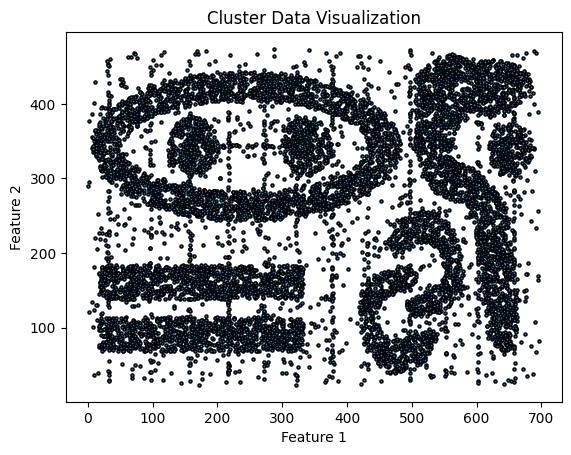


Running SLink with k = 2
Time = 4.0574 seconds, Silhouette Score = 0.4515, Calinski-Harabasz Index = 11381.9122


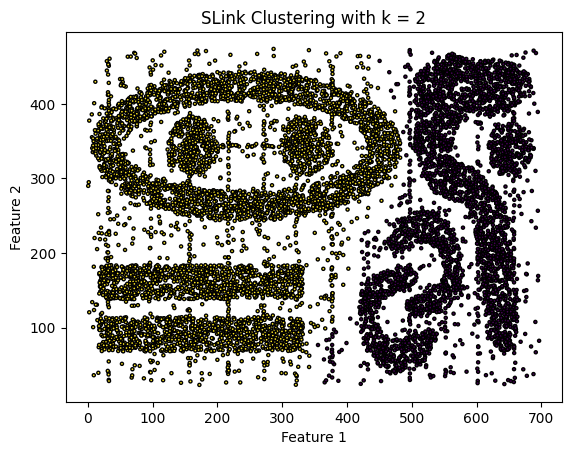

Silhouette Score = 0.4515, Calinski-Harabasz Index = 11381.9122

Running SLink with k = 3
Time = 3.9596 seconds, Silhouette Score = 0.4060, Calinski-Harabasz Index = 9904.4899


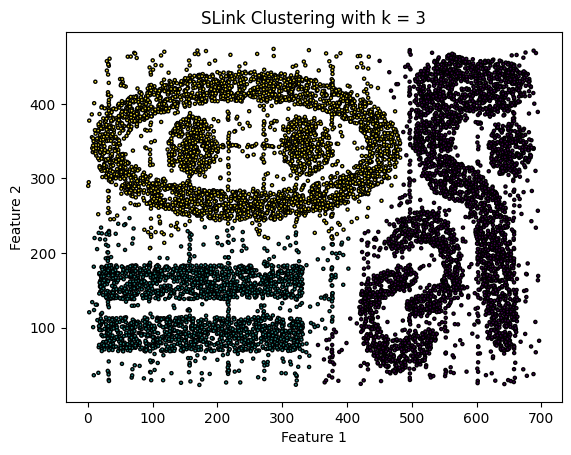

Silhouette Score = 0.4060, Calinski-Harabasz Index = 9904.4899

Running SLink with k = 4
Time = 4.1027 seconds, Silhouette Score = 0.3881, Calinski-Harabasz Index = 10233.0456


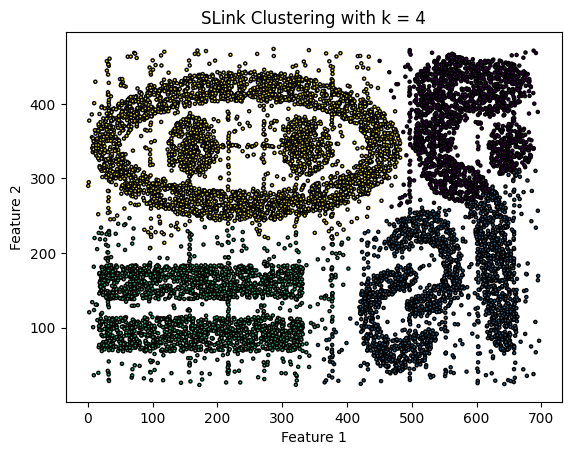

Silhouette Score = 0.3881, Calinski-Harabasz Index = 10233.0456

Running SLink with k = 5
Time = 3.9875 seconds, Silhouette Score = 0.4409, Calinski-Harabasz Index = 13074.9625


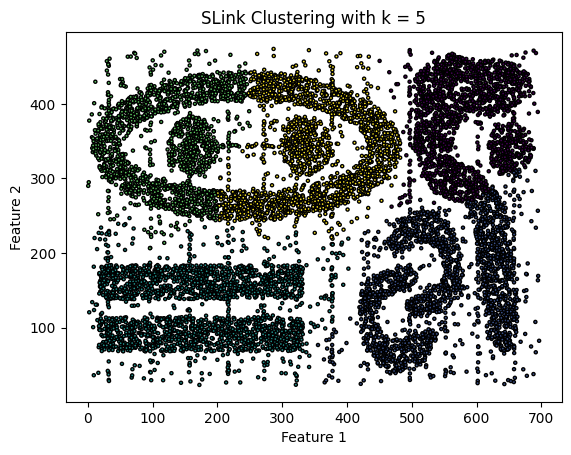

Silhouette Score = 0.4409, Calinski-Harabasz Index = 13074.9625

Running SLink with k = 6
Time = 4.0265 seconds, Silhouette Score = 0.4269, Calinski-Harabasz Index = 13178.3415


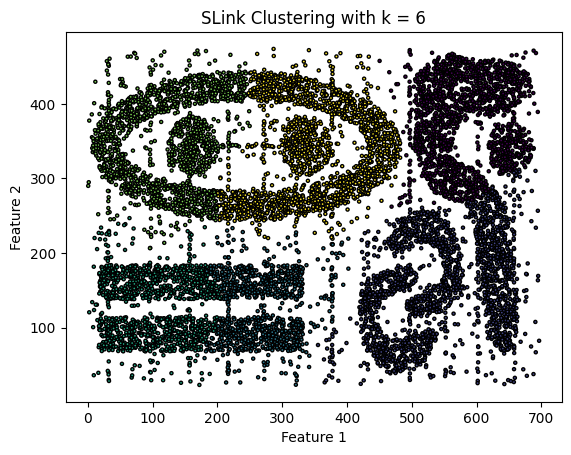

Silhouette Score = 0.4269, Calinski-Harabasz Index = 13178.3415

Running SLink with k = 7
Time = 4.0588 seconds, Silhouette Score = 0.4159, Calinski-Harabasz Index = 13134.8626


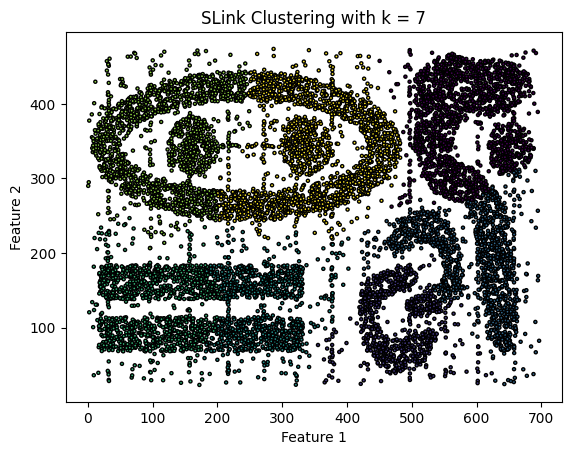

Silhouette Score = 0.4159, Calinski-Harabasz Index = 13134.8626

Running SLink with k = 8
Time = 4.0825 seconds, Silhouette Score = 0.3815, Calinski-Harabasz Index = 12665.5786


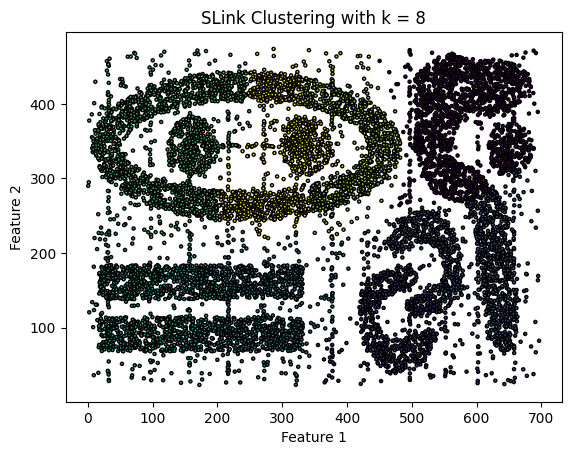

Silhouette Score = 0.3815, Calinski-Harabasz Index = 12665.5786

Running SLink with k = 9
Time = 4.0028 seconds, Silhouette Score = 0.3672, Calinski-Harabasz Index = 12144.3454


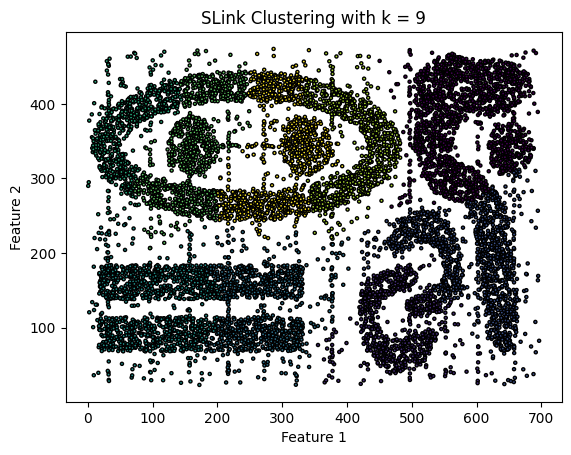

Silhouette Score = 0.3672, Calinski-Harabasz Index = 12144.3454


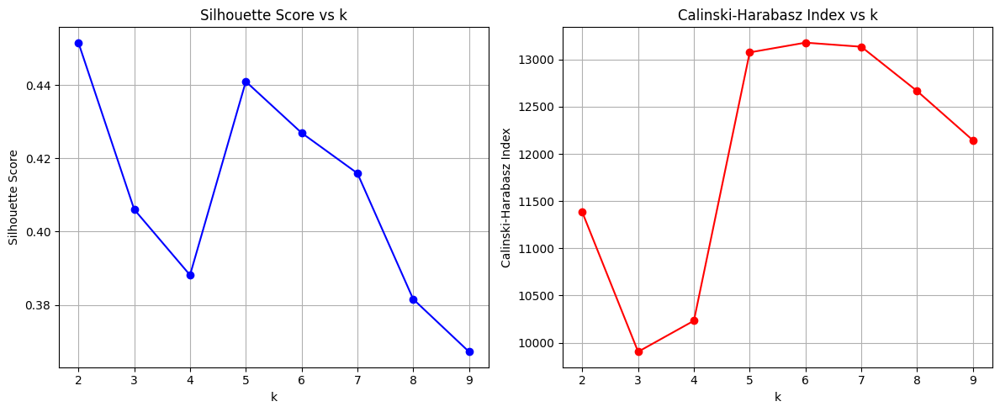

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, fcluster
import time

def load_data(file_path):
    data = np.loadtxt(file_path)
    return data

def slink(X, k):
    start_time = time.time()
    Z = linkage(X, method='ward')
    labels = fcluster(Z, t=k, criterion='maxclust')  
    end_time = time.time()
    elapsed_time = end_time - start_time
    if len(set(labels)) > 1: 
        silhouette = silhouette_score(X, labels)
        calinski = calinski_harabasz_score(X, labels)
    else:
        silhouette, calinski = -1, -1
    
    print(f"Time = {elapsed_time:.4f} seconds, Silhouette Score = {silhouette:.4f}, Calinski-Harabasz Index = {calinski:.4f}")
    
    return labels, silhouette, calinski

file_path = "/kaggle/input/clusterdata1/clusterData1.10k.dat"
clusterData1 = load_data(file_path)
print(f"Data shape: {clusterData1.shape}")

plt.scatter(clusterData1[:, 0], clusterData1[:, 1], s=5, edgecolors='k')
plt.title("Cluster Data Visualization")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

k_values = [2, 3, 4, 5, 6, 7, 8, 9]
results = {}

for k in k_values:
    print(f"\nRunning SLink with k = {k}")
    labels, silhouette, calinski = slink(clusterData1, k)
    results[k] = {'silhouette': silhouette, 'calinski': calinski, 'labels': labels}
    plt.scatter(clusterData1[:, 0], clusterData1[:, 1], c=labels, s=5, cmap='viridis', edgecolors='k')
    plt.title(f"SLink Clustering with k = {k}")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()
    
    print(f"Silhouette Score = {silhouette:.4f}, Calinski-Harabasz Index = {calinski:.4f}")


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(k_values, [results[k]['silhouette'] for k in k_values], marker='o', linestyle='-', color='b')
plt.title("Silhouette Score vs k")
plt.xlabel("k")
plt.ylabel("Silhouette Score")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(k_values, [results[k]['calinski'] for k in k_values], marker='o', linestyle='-', color='r')
plt.title("Calinski-Harabasz Index vs k")
plt.xlabel("k")
plt.ylabel("Calinski-Harabasz Index")
plt.grid(True)

plt.tight_layout()
plt.show()

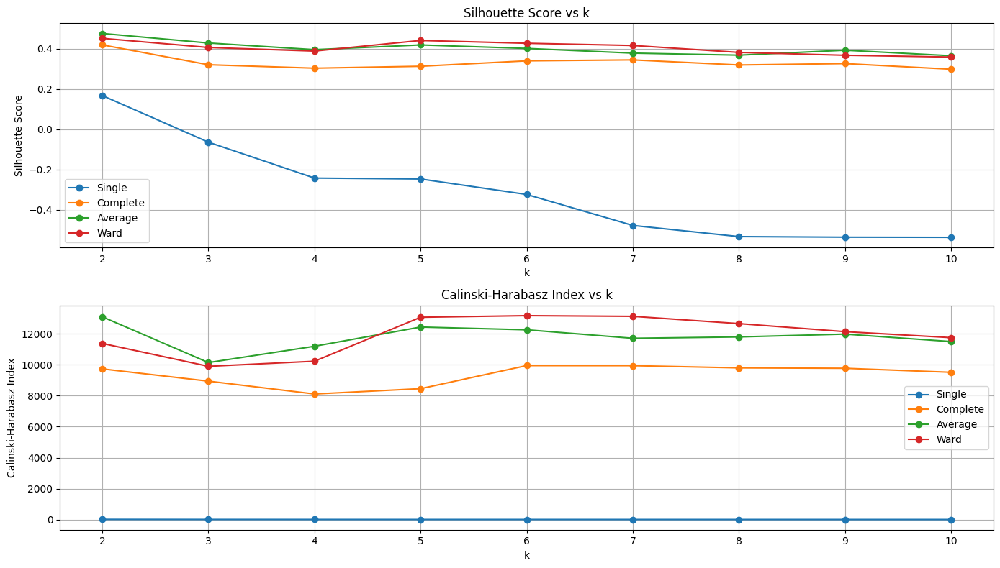

In [12]:
import matplotlib.pyplot as plt
import numpy as np

k_values = [2, 3, 4, 5, 6, 7, 8, 9, 10]
single_silhouette = [0.1671, -0.0645, -0.2429, -0.2474, -0.3243, -0.4782, -0.5335, -0.5364, -0.5372]
complete_silhouette = [0.4188, 0.3202, 0.3031, 0.3126, 0.3395, 0.3442, 0.3190, 0.3259, 0.2979]
average_silhouette = [0.4757, 0.4283, 0.3951, 0.4186, 0.4012, 0.3779, 0.3678, 0.3923, 0.3649]
ward_silhouette = [0.4515, 0.4060, 0.3881, 0.4409, 0.4269, 0.4159, 0.3815, 0.3672, 0.3584]

single_ch = [11.6186, 6.7239, 5.3141, 4.2299, 4.3362, 3.6164, 3.1903, 2.9350, 2.9165]
complete_ch = [9736.9948, 8945.3514, 8114.7462, 8459.0289, 9952.3427, 9947.8351, 9803.3964, 9776.5075, 9517.1750]
average_ch = [13104.3581, 10145.6088, 11199.3260, 12441.7454, 12264.6614, 11715.2987, 11803.1123, 11985.4603, 11502.6391]
ward_ch = [11381.9122, 9904.4899, 10233.0456, 13074.9625, 13178.3415, 13134.8626, 12665.5786, 12144.3454, 11757.0790]

plt.figure(figsize=(14, 8))

plt.subplot(2, 1, 1)
plt.plot(k_values, single_silhouette, marker='o', label='Single')
plt.plot(k_values, complete_silhouette, marker='o', label='Complete')
plt.plot(k_values, average_silhouette, marker='o', label='Average')
plt.plot(k_values, ward_silhouette, marker='o', label='Ward')
plt.title('Silhouette Score vs k')
plt.xlabel('k')
plt.ylabel('Silhouette Score')
plt.legend()
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(k_values, single_ch, marker='o', label='Single')
plt.plot(k_values, complete_ch, marker='o', label='Complete')
plt.plot(k_values, average_ch, marker='o', label='Average')
plt.plot(k_values, ward_ch, marker='o', label='Ward')
plt.title('Calinski-Harabasz Index vs k')
plt.xlabel('k')
plt.ylabel('Calinski-Harabasz Index')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()